Migration Guide (Azure $\rightarrow$ Oracle 12 GB RAM VM)

Step A: Export Non-Git Assets & Configs from the Azure VMBefore stopping the Azure machine, connect to it via SSH and pack your data files (data.parquet and world_boundaries.geojson), PDF files (chemrxiv-2025-d2zc8.pdf and original_final.pdf), and existing proxy/service configs into a single backup archive[cite: 1, 6, 7]:

# 1. On the Azure VM: create a migration backup bundle
mkdir -p ~/azure_migration_backup
cp -r /path/to/CS-Explorer-App/data ~/azure_migration_backup/
cp -r /path/to/CS-Explorer-App/www ~/azure_migration_backup/
sudo cp -r /etc/nginx/sites-available ~/azure_migration_backup/nginx_sites 2>/dev/null || true
sudo cp /etc/systemd/system/*shiny* /etc/systemd/system/*cs* ~/azure_migration_backup/ 2>/dev/null || true
tar -czvf ~/cs_explorer_backup.tar.gz -C ~/azure_migration_backup .

# 2. On your local laptop: download the backup archive from Azure
scp user@<AZURE_IP>:~/cs_explorer_backup.tar.gz ./

### 1. Cleaned `requirements.txt` for Oracle Cloud (ARM64 / Ampere A1)

Your original `requirements.txt` contains 99 packages, including heavy development tools and unused frameworks (`streamlit==1.40.1`, `altair==5.4.1`, `pydeck==0.9.3`, `ipython==8.12.3`, `jupyter_core==5.8.1`, `GitPython==3.1.50`, and `questionary==2.1.0`) that are not imported anywhere in the project[cite: 1, 3, 6, 7].

Replace `requirements.txt` with this streamlined list of the exact packages used by `app.py` and `utils/functions.py` so `pip` installs pre-compiled `aarch64` (ARM64) binary wheels on the Oracle VM in under 30 seconds[cite: 3, 6, 7]:

```txt
branca==0.8.2
certifi==2026.6.17
click==8.1.8
folium==0.18.0
geopandas==0.13.2
h11==0.16.0
htmltools==0.5.3
Jinja2==3.1.6
narwhals==1.42.1
numpy==1.24.4
orjson==3.10.15
packaging==24.2
pandas==2.0.3
plotly==6.9.0
pyarrow==17.0.0
pyogrio==0.9.0
pyproj==3.5.0
python-dateutil==2.9.0.post0
python-multipart==0.0.20
pytz==2026.2
requests==2.32.4
shapely==2.0.7
shiny==1.1.0
shinywidgets==0.3.3
starlette==0.44.0
 tzdata==2026.3
urllib3==2.2.3
uvicorn==0.33.0
watchfiles==0.24.0
websockets==13.1
xyzservices==2026.3.0

```

---

### 2. Step-by-Step Migration Guide (Azure $\rightarrow$ Oracle 12 GB RAM VM)

#### Step A: Export Non-Git Assets & Configs from the Azure VM

Before stopping the Azure machine, connect to it via SSH and pack your data files (`data.parquet` and `world_boundaries.geojson`), PDF files (`chemrxiv-2025-d2zc8.pdf` and `original_final.pdf`), and existing proxy/service configs into a single backup archive[cite: 1, 6, 7]:

```bash
# 1. On the Azure VM: create a migration backup bundle
mkdir -p ~/azure_migration_backup
cp -r /path/to/CS-Explorer-App/data ~/azure_migration_backup/
cp -r /path/to/CS-Explorer-App/www ~/azure_migration_backup/
sudo cp -r /etc/nginx/sites-available ~/azure_migration_backup/nginx_sites 2>/dev/null || true
sudo cp /etc/systemd/system/*shiny* /etc/systemd/system/*cs* ~/azure_migration_backup/ 2>/dev/null || true
tar -czvf ~/cs_explorer_backup.tar.gz -C ~/azure_migration_backup .

# 2. On your local laptop: download the backup archive from Azure
scp user@<AZURE_IP>:~/cs_explorer_backup.tar.gz ./

```

---

#### Step B: Provision & Prepare the Oracle Ampere A1 VM (2 OCPUs, 12 GB RAM)

Once the client grants you access (or shares the SSH IP of the new **Ubuntu 24.04 / 22.04 `VM.Standard.A1.Flex**` instance with ports `80` and `443` opened in the Oracle VCN Security List), SSH into the Oracle VM and run:

```bash
# 1. Update packages and install system dependencies
sudo apt update && sudo apt upgrade -y
sudo apt install -y python3-venv python3-pip python3-dev nginx certbot python3-certbot-nginx git iptables-persistent

# 2. Open HTTP (80) and HTTPS (443) in Oracle's OS-level iptables firewall
sudo iptables -I INPUT 6 -m state --state NEW -p tcp --dport 80 -j ACCEPT
sudo iptables -I INPUT 6 -m state --state NEW -p tcp --dport 443 -j ACCEPT
sudo netfilter-persistent save

# 3. Clone your repository and set up the Python virtual environment
cd ~
git clone https://github.com/santi-rios/CS-Explorer-App.git
cd ~/CS-Explorer-App
python3 -m venv .venv
source .venv/bin/activate
pip install --upgrade pip
pip install -r requirements.txt

```

(If `data/data.parquet`, `data/world_boundaries.geojson`, or `www/original_final.pdf` are not tracked in GitHub, upload `cs_explorer_backup.tar.gz` to the Oracle VM via `scp` and extract `data/` and `www/` into `~/CS-Explorer-App/`.)

---

#### Step C: Create the `systemd` Service File (Multi-Worker for 12 GB RAM)

Because your `app.py` runs on port `8888` and the Oracle VM has 12 GB of RAM and 2 ARM64 OCPUs, you can run `uvicorn` with 2 workers so multiple visitors can play animations simultaneously[cite: 3, 7].

Create `/etc/systemd/system/cs-explorer.service`:

```bash
sudo tee /etc/systemd/system/cs-explorer.service > /dev/null << 'EOF'
[Unit]
Description=Chemical Space Explorer Shiny for Python App
After=network.target

[Service]
Type=simple
User=ubuntu
WorkingDirectory=/home/ubuntu/CS-Explorer-App
Environment="PATH=/home/ubuntu/CS-Explorer-App/.venv/bin"
ExecStart=/home/ubuntu/CS-Explorer-App/.venv/bin/uvicorn app:app --host 127.0.0.1 --port 8888 --workers 2 --ws-ping-interval 25 --ws-ping-timeout 60
Restart=always
RestartSec=3

[Install]
WantedBy=multi-user.target
EOF

# Enable and start the service
sudo systemctl daemon-reload
sudo systemctl enable --now cs-explorer
sudo systemctl status cs-explorer

```

---

#### Step D: Configure Nginx Reverse Proxy with WebSockets & SSL

Shiny for Python relies on `websockets` to stream reactive updates and Folium map clicks (`map_click_iso`) between the browser and the server[cite: 3, 6, 7]. Create `/etc/nginx/sites-available/cs-explorer`:

```bash
sudo tee /etc/nginx/sites-available/cs-explorer > /dev/null << 'EOF'
map $http_upgrade $connection_upgrade {
    default upgrade;
    ''      close;
}

server {
    listen 80;
    server_name yourdomain.com www.yourdomain.com; # <-- Replace with your actual domain (or _ if IP-only)

    # Silently drop automated PHP bot scans
    location ~* \.php$ {
        return 444;
    }

    location / {
        proxy_pass http://127.0.0.1:8888;
        proxy_http_version 1.1;
        proxy_set_header Upgrade $http_upgrade;
        proxy_set_header Connection $connection_upgrade;
        proxy_set_header Host $host;
        proxy_set_header X-Real-IP $remote_addr;
        proxy_set_header X-Forwarded-For $proxy_add_x_forwarded_for;
        proxy_set_header X-Forwarded-Proto $scheme;
        proxy_read_timeout 3600s;
        proxy_send_timeout 3600s;
        proxy_buffering off;
    }
}
EOF

sudo ln -sf /etc/nginx/sites-available/cs-explorer /etc/nginx/sites-enabled/
sudo rm -f /etc/nginx/sites-enabled/default
sudo nginx -t && sudo systemctl reload nginx

```

Finally, once you update your DNS `A` record in Cloudflare to point to the new Oracle VM's public IP address:

* **If Cloudflare Proxy (Orange Cloud) is OFF (DNS Only):** Run `sudo certbot --nginx -d yourdomain.com -d [www.yourdomain.com](https://www.yourdomain.com)` to automatically install and auto-renew a free Let's Encrypt HTTPS certificate.
* **If Cloudflare Proxy (Orange Cloud) is ON:** In Cloudflare, go to **SSL/TLS $\rightarrow$ Origin Server $\rightarrow$ Create Certificate**, paste the `.pem` and `.key` files onto the Oracle VM (or copy the existing ones from your Azure backup), and set SSL/TLS encryption mode to **Full (Strict)**.

---

### 3. Actualización de la Cotización en Español (Incluyendo el Rediseño para 12 GB RAM)

Since you also redesigned the interface to take advantage of the 12 GB RAM server—adding KPI Value Boxes, the 3-mode interactive map (Superzip proportional/color-intensity bubbles, circular flag badges, and shaded polygons), flags on trend lines, and the 60fps animated bubble ranking explorer—here is the updated **Extra A** row in Spanish so you can present the full value of your work to the client:

| Servicio / Módulo | Descripción Detallada de Entregables | Tiempo Estimado | Costo Estimado (MXN) | Costo Estimado (USD) |
| --- | --- | --- | --- | --- |
| **Migración Base (Azure $\rightarrow$ Oracle Cloud 12 GB RAM)** | • Respaldo integral del servidor Azure y configuración de red/cortafuegos (`VCN` + `iptables`) en Oracle Cloud Ampere A1.<br>

<br>• Despliegue multi-proceso (`uvicorn` + `systemd`) optimizado para 12 GB RAM, proxy inverso **Nginx** con soporte para **WebSockets**, certificados **SSL/HTTPS** y transición de **DNS en Cloudflare** sin caída del servicio[cite: 3, 7]. | 9 – 12 hrs | $4,500 – $5,700 MXN | $245 – $315 USD |
| **Rediseño Visual Interactivo y Optimización en RAM (12 GB Upgrade)** | • **Tarjetas Ejecutivas de Indicadores (KPI Value Boxes):** Paneles superiores fijos y dinámicos que calculan en tiempo real el país líder, cuota combinada y redes de colaboración activas según los filtros seleccionados.

<br>

<br>• **Mapa Geopolítico en 3 Modos Visuales:** Selector en vivo entre *(1) Burbujas proporcionales con intensidad de color (estilo Superzip)*, *(2) Insignias circulares con banderas nacionales* y *(3) Polígonos geográficos sombreados*, acompañado de buscador rápido de países.

<br>

<br>• **Nuevas Animaciones y Gráficas del Artículo:** Gráfica animada de burbujas y ranking global (1996–2022), vista ejecutiva lado a lado, banderas en líneas de tendencia, ajuste exponencial de China ($R^2 = 0.98$), escala logarítmica en subespacios químicos y marcadores de eventos históricos (Crisis 2008, Acuerdos Bilaterales 2009–2017, China Initiative 2018 y COVID-19 2020)[cite: 2, 6].

<br>

<br>• **Caché en Memoria RAM:** Precarga en memoria de `data.parquet` y geometrías `GeoJSON` para respuesta instantánea.

 | 8 – 10 hrs | $3,800 – $4,800 MXN | $210 – $265 USD |
| **Protección Anti-Suspensión, Monitoreo y Respaldos (Opcional)** | • Configuración de candados de presupuesto en **$0 USD** / servicio *keep-alive* para evitar la suspensión automática por inactividad de Oracle.<br>

<br>• Alertas automáticas por correo ante caídas o alto uso de RAM (**OCI Monitoring**) y respaldos semanales automáticos del disco (**OCI Block Volume Backups**). | 3.5 – 5 hrs | $1,800 – $2,400 MXN | $100 – $130 USD |
| **Total Proyecto Completo** | **Migración llave en mano + Rediseño de la App para 12 GB RAM + Monitoreo y Respaldos** | **20.5 – 27 hrs** | **$10,100 – $12,900 MXN** | **$555 – $710 USD** |

* Write a systemd keep-alive script to prevent Oracle Cloud from reclaiming the Free Tier VM during low-traffic weeks
* Add a download button in the Shiny UI so users can export the filtered dataset or Plotly figures as CSV/PNG
* Draft a short cover message in Spanish to accompany the quotation table when sending it to the client

-------------

# 🧪 Manual Interactivo: Cómo funciona *Chemical Space Explorer* y su Servidor en la Nube

¡Bienvenida! Este cuaderno interactivo (*Jupyter Notebook*) está diseñado para que puedas explorar, modificar y administrar tu aplicación web sin temor a romper nada. 

### 🏗️ 1. ¿Cómo funciona la aplicación por dentro?
Piensa en el proyecto como un restaurante dividido en **4 áreas principales**:

1. **Los Ingredientes (`data/data.parquet` y `world_boundaries.geojson`):** Son los archivos donde viven los datos procesados del artículo (los 15.7 millones de compuestos, porcentajes por país de 1996 a 2022, regiones y coordenadas). Usamos el formato `.parquet` porque se lee muchísimo más rápido que un archivo de Excel o CSV.
2. **La Cocina (`utils/functions.py`):** Es el archivo de Python que toma los datos crudos, los filtra (por año, región o tipo de compuesto) y construye las gráficas de **Plotly** y los mapas de **Folium**.
3. **El Comedor / Interfaz (`app.py`):** Es la aplicación de **Shiny for Python**. Define dónde van los botones, pestañas y menús desplegables (`app_ui`), y contiene una función `server()` que escucha qué país o año seleccionó el usuario para pedirle a `functions.py` una gráfica nueva al instante.
4. **El Edificio (`Servidor Oracle Cloud` + `Nginx` + `Uvicorn`):** 
   * **Uvicorn** mantiene encendida tu aplicación de Python en el puerto interno `8888`.
   * **Systemd (`cs-explorer.service`)** es el "vigilante": si el servidor se reinicia o la app falla, la vuelve a encender automáticamente.
   * **Nginx** es el "recepcionista": recibe a los visitantes que entran con `https://tudominio.com` (puerto 443) y los conecta de forma segura con tu app.

💻 Celda 2 (Código): Módulo 1 — Clonando el Proyecto desde GitHub y Preparando el Entorno

```python
# En Google Colab, las líneas que empiezan con "!" ejecutan comandos de terminal (Linux),
# exactamente igual a como lo harás dentro de tu servidor de Oracle Cloud.

# 1. Descargamos ("clonamos") el código de la aplicación desde GitHub
!git clone https://github.com/santi-rios/CS-Explorer-App.git

# 2. Instalamos las librerías necesarias para explorar los datos y mapas
!pip install -q plotly folium pandas pyarrow branca

# 3. Nos movemos dentro de la carpeta del proyecto
%cd CS-Explorer-App
!ls -la
```

## 📊 2. Explorando la Base de Datos (`data/data.parquet`)
En lugar de cargar hojas de cálculo pesadas cada vez que un usuario hace clic, la aplicación utiliza `@lru_cache` (memoria caché en RAM) para leer el archivo `data/data.parquet` una sola vez.

Veamos cómo luce la tabla por dentro y cómo filtramos los datos de **China (`CN`)**, **Estados Unidos (`US`)** e **India (`IN`)** tal como lo hace la función `get_display_data()` en `utils/functions.py`.

📘 Celda 3 (Markdown): Módulo 2 — Entendiendo los Datos (data.parquet)

## 📊 2. Explorando la Base de Datos (`data/data.parquet`)
En lugar de cargar hojas de cálculo pesadas cada vez que un usuario hace clic, la aplicación utiliza `@lru_cache` (memoria caché en RAM) para leer el archivo `data/data.parquet` una sola vez.

Veamos cómo luce la tabla por dentro y cómo filtramos los datos de **China (`CN`)**, **Estados Unidos (`US`)** e **India (`IN`)** tal como lo hace la función `get_display_data()` en `utils/functions.py`.

💻 Celda 4 (Código): Cargando y Filtrando el Dataset Real

```python
import pandas as pd

# Leemos el archivo Parquet de la aplicación
df = pd.read_parquet("data/data.parquet")

print(f"Total de filas en la base de datos: {len(df):,}")
print("Columnas disponibles:", df.columns.tolist())

# Ejemplo práctico: Filtrar contribuciones individuales (sin colaboración)
# en todo el espacio químico ("All") para China, EE. UU. e India entre 2010 y 2022
filtro = (
    (df["is_collab"] == False)
    & (df["chemical"] == "All")
    & (df["iso2c"].isin(["CN", "US", "IN"]))
    & (df["year"] >= 2010)
    & (df["year"] <= 2022)
)

df_ejemplo = df[filtro][
    ["year", "country", "iso2c", "region", "percentage", "cc"]
].sort_values(["country", "year"])
df_ejemplo.head(10)
```

📘 Celda 5 (Markdown): Módulo 3 — Creando Gráficas Interactivas y Mapas como en la App

## 📈 3. ¿Cómo se construyen las Gráficas (Plotly) y los Mapas (Folium)?
En tu aplicación, cuando alguien cambia un filtro en `app.py`, Shiny ejecuta una función de `utils/functions.py` que devuelve un objeto de **Plotly** o **Folium**.

 ¡Puedes probar y modificar el diseño de cualquier gráfica aquí mismo antes de subir cambios al servidor! Ejecuta las siguientes dos celdas para ver:
1. La gráfica interactiva de tendencias con el cruce histórico de 2013 y las banderas.
2. El mapa interactivo con burbujas proporcionales e insignias de banderas.

💻 Celda 6 (Código): Generando la Gráfica Interactiva con Plotly

```python
import numpy as np
import plotly.graph_objects as go


def iso_to_flag_emoji(iso2c: str) -> str:
  """Convierte el código ISO de 2 letras (ej. 'CN') en el emoji de su bandera."""
  if not isinstance(iso2c, str) or len(iso2c.strip()) != 2:
    return '🏳️'
  return ''.join(chr(127397 + ord(c)) for c in iso2c.strip().upper())


# Creamos una figura interactiva de Plotly
fig = go.Figure()

paises = ['CN', 'US', 'IN', 'DE', 'JP']
df_plot = df[
    (df['is_collab'] == False)
    & (df['chemical'] == 'All')
    & (df['iso2c'].isin(paises))
].sort_values('year')

for iso in paises:
  datos_pais = df_plot[df_plot['iso2c'] == iso]
  if datos_pais.empty:
    continue
  nombre = datos_pais['country'].iloc[0]
  color = datos_pais['cc'].iloc[0]
  bandera = iso_to_flag_emoji(iso)

  fig.add_trace(
      go.Scatter(
          x=datos_pais['year'],
          y=datos_pais['percentage'],
          mode='lines+markers',
          name=f'{bandera} {nombre}',
          line=dict(color=color, width=2.5),
          hovertemplate=(
              f'<b>{bandera} {nombre}</b><br>Año: %{{x}}<br>Participación:'
              ' <b>%{y:.2f}%</b><extra></extra>'
          ),
      )
  )

# Añadimos la curva de ajuste exponencial de China del artículo: 1.33 * e^(0.1372 * (t - 1996))
anios = np.arange(1996, 2023)
ajuste_exp = 1.33 * np.exp(0.1372 * (anios - 1996))
fig.add_trace(
    go.Scatter(
        x=anios,
        y=ajuste_exp,
        mode='lines',
        name='Ajuste Exponencial China (R² = 0.98)',
        line=dict(color='#c5051b', width=1.5, dash='dot'),
    )
)

# Marcadores históricos (Crisis 2008, Cruce 2013, COVID-19 2020)
fig.add_vline(x=2013, line_dash='dash', line_color='#c5051b')
fig.add_annotation(
    x=2013,
    y=36,
    text='<b>2013:</b> China supera a EE. UU.',
    showarrow=True,
    arrowhead=2,
    ax=-60,
    ay=-20,
)

fig.update_layout(
    title=(
        '<b>Participación en el Espacio Químico (1996–2022)</b> — Prueba'
        ' interactiva'
    ),
    xaxis_title='Año',
    yaxis=dict(title='Porcentaje de Nuevas Sustancias (%)', ticksuffix='%'),
    template='plotly_white',
    hovermode='x unified',
    height=500,
)

fig.show()
```

💻 Celda 7 (Código): Generando el Mapa Interactivo con Folium

```python
import branca.colormap as cm
import folium

# Obtenemos la lista única de países y su promedio de contribución en el espacio químico
resumen_paises = (
    df[(df['is_collab'] == False) & (df['chemical'] == 'All')]
    .groupby(
        ['iso2c', 'country', 'lat', 'lng', 'region'], as_index=False
    )['percentage']
    .mean()
    .dropna(subset=['lat', 'lng'])
)

mapa = folium.Map(
    location=[20, 10],
    zoom_start=2,
    tiles='https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png',
    attr='OpenStreetMap & CARTO',
)

max_val = resumen_paises['percentage'].max()
escala_color = cm.LinearColormap(
    colors=['#440154', '#3b528b', '#21918c', '#5ec962', '#fde725'],
    vmin=0,
    vmax=np.sqrt(max_val),
    caption='Contribución Promedio al CS (%) [Escala √]',
)

for _, fila in resumen_paises.iterrows():
  iso = str(fila['iso2c']).upper()
  promedio = float(fila['percentage'])
  radio = float(np.clip(5 + np.sqrt(max(promedio, 0.05)) * 5, 5, 32))
  color_burbuja = escala_color(np.sqrt(max(promedio, 0)))

  folium.CircleMarker(
      location=[fila['lat'], fila['lng']],
      radius=radio,
      color='#1f2937',
      weight=1,
      fill=True,
      fill_color=color_burbuja,
      fill_opacity=0.75,
      tooltip=(
          f"<b>{iso_to_flag_emoji(iso)} {fila['country']} ({iso})</b><br>Prom."
          f' 1996-2022: <b>{promedio:.2f}%</b>'
      ),
  ).add_to(mapa)

escala_color.add_to(mapa)
mapa
```

📘 Celda 8 (Markdown): Módulo 4 — Cómo funciona la Reactividad en Shiny (app.py)

## ⚡ 4. ¿Cómo conecta Shiny los botones con las gráficas? (Reactividad)
Cuando abres `app.py`, verás dos bloques principales dentro de `create_app()`:

1. **`app_ui` (La Interfaz Visual):**
   Aquí se crean los controles con un identificador único (`id`). Por ejemplo:
   ```python
   # Crea el deslizador de años con el ID "years"
   ui.input_slider("years", "📅 Year Range:", min=1996, max=2022, value=[1996, 2022])
   
   # Crea el espacio donde se dibujará la gráfica con el ID "main_plot"
   ui.output_ui("main_plot")

`server(input, output, session)` (El Cerebro Reactivo):
Cada vez que mueves el deslizador "years", Shiny detecta automáticamente que input.years() cambió y vuelve a ejecutar cualquier función que dependa de él:

```python
@output
@render.ui
def main_plot():
    # Lee qué años y qué subespacio químico están seleccionados en este instante
    rango_anios = input.years()
    subespacio = input.chemical_category()
    ...
    return figure_to_html(create_trends_plot(...))
    ```
    

---

#### 📘 Celda 9 (Markdown): Módulo 5 — Guía Práctica de Git, Conexión SSH y Servidor Oracle Cloud
```markdown
## 🛠️ 5. Guía de Supervivencia: Git, Conexión SSH y Administración del Servidor Oracle

Aquí tienes tu "hoja de referencia rápida" (*cheat sheet*) para conectarte a tu servidor en Oracle Cloud, actualizar la aplicación con Git y revisar que todo funcione correctamente.

---

### 🔐 A. ¿Cómo conectarte a la máquina virtual de Oracle Cloud (SSH)?
Tu servidor en Oracle Cloud es una computadora con **Ubuntu Linux** encendida las 24 horas. Para entrar a su terminal desde tu computadora (Windows PowerShell, Mac Terminal o Linux):

1. Guarda tu archivo de llave privada (por ejemplo, `oracle_key.key`) en una carpeta segura en tu computadora.
2. Abre tu terminal y ejecuta:
   ```bash
   ssh -i /ruta/a/tu/oracle_key.key ubuntu@IP_PUBLICA_DEL_SERVIDOR

B. Los 4 Comandos Básicos de Git (Cómo subir y descargar cambios)

Git es como una máquina del tiempo que sincroniza el código entre tu computadora, GitHub y el Servidor de Oracle.

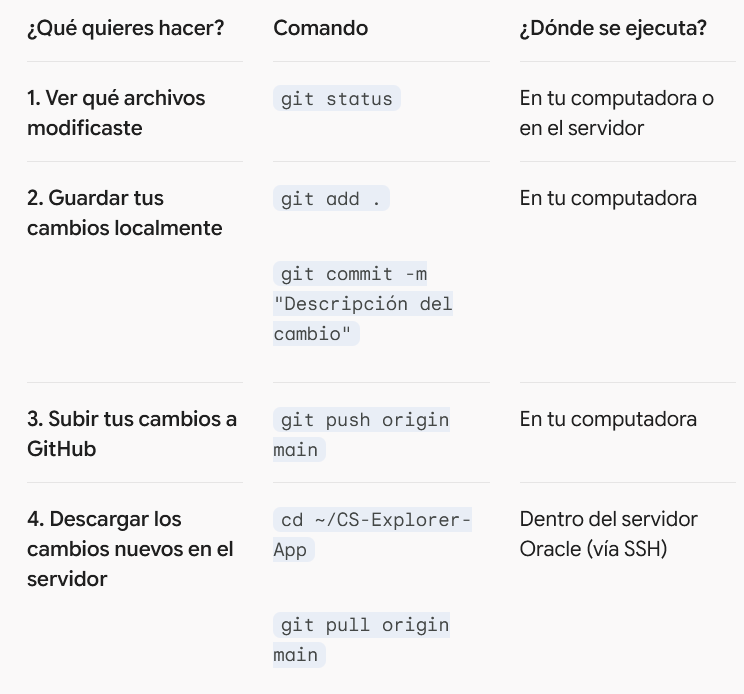

🚀 C. Cómo Administrar tu Aplicación en el Servidor Oracle

Una vez conectada por SSH al servidor de Oracle (ubuntu@...), estos son los únicos comandos que necesitas para controlar tu aplicación:

    Ver si la aplicación está encendida y funcionando sin errores:
    Bash

    sudo systemctl status cs-explorer

    (Busca la palabra active (running) en color verde. Presiona la tecla q para salir).

    Reiniciar la aplicación (después de hacer un git pull con cambios de código):
    Bash

    sudo systemctl restart cs-explorer

    Ver el registro de actividad o errores en vivo (Logs):
    Bash

    sudo journalctl -u cs-explorer -f

    (Muestra en tiempo real lo que hace la app; presiona Ctrl + C para salir).

    Verificar cuánta memoria RAM (de los 12 GB) y procesador está usando el servidor:
    Bash

    htop

    (O bien free -h para un resumen rápido de la memoria RAM libre).


---

### Bonus: Generador Automático del Archivo `.ipynb`

If you want to generate the actual `Tutorial_CS_Explorer.ipynb` file directly on your laptop right now and upload it straight to Google Drive / Google Colab to share a link with her, save and run this tiny Python script locally:

```python
import json

cells = [
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "# 🧪 Manual Interactivo: Cómo funciona *Chemical Space Explorer* y su Servidor en la Nube\n\n",
            "¡Bienvenida! Este cuaderno interactivo (*Jupyter Notebook*) está diseñado para que puedas explorar, modificar y administrar tu aplicación web sin temor a romper nada.\n\n",
            "### 🏗️ 1. ¿Cómo funciona la aplicación por dentro?\n",
            "1. **Los Ingredientes (`data/data.parquet` y `world_boundaries.geojson`):** Archivos con los datos procesados del artículo (1996–2022).\n",
            "2. **La Cocina (`utils/functions.py`):** Filtra los datos y construye las gráficas de **Plotly** y los mapas de **Folium**.\n",
            "3. **El Comedor (`app.py`):** La aplicación de **Shiny for Python** que conecta los botones de la interfaz (`app_ui`) con la lógica reactiva (`server`).\n",
            "4. **El Servidor (`Oracle Cloud` + `Nginx` + `Systemd`):** Mantiene la aplicación encendida 24/7 con HTTPS seguro."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "# 1. Clonamos el repositorio desde GitHub e instalamos dependencias en Colab\n",
            "!git clone https://github.com/santi-rios/CS-Explorer-App.git\n",
            "!pip install -q plotly folium pandas pyarrow branca\n",
            "%cd CS-Explorer-App\n",
            "!ls -la"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "## 📊 2. Explorando la Base de Datos (`data/data.parquet`)\n",
            "Veamos cómo luce la tabla por dentro y cómo filtramos los datos de **China (`CN`)**, **Estados Unidos (`US`)** e **India (`IN`)**."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "import pandas as pd\n\n",
            "df = pd.read_parquet('data/data.parquet')\n",
            "print(f'Total de filas en la base de datos: {len(df):,}')\n",
            "print('Columnas disponibles:', df.columns.tolist())\n\n",
            "filtro = (\n",
            "    (df['is_collab'] == False) &\n",
            "    (df['chemical'] == 'All') &\n",
            "    (df['iso2c'].isin(['CN', 'US', 'IN'])) &\n",
            "    (df['year'] >= 2010)\n",
            ")\n",
            "df[filtro][['year', 'country', 'iso2c', 'region', 'percentage']].sort_values(['country', 'year']).head(10)"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "## 📈 3. Creando las Gráficas Interactivas (Plotly) y Mapas (Folium)\n",
            "Aquí puedes probar modificaciones de colores, títulos o tamaños de burbuja antes de pasarlos a `utils/functions.py`."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "import plotly.graph_objects as go\n",
            "import numpy as np\n\n",
            "def iso_to_flag_emoji(iso2c: str) -> str:\n",
            "    if not isinstance(iso2c, str) or len(iso2c.strip()) != 2:\n",
            "        return '🏳️'\n",
            "    return ''.join(chr(127397 + ord(c)) for c in iso2c.strip().upper())\n\n",
            "fig = go.Figure()\n",
            "paises = ['CN', 'US', 'IN', 'DE', 'JP']\n",
            "df_plot = df[(df['is_collab'] == False) & (df['chemical'] == 'All') & (df['iso2c'].isin(paises))].sort_values('year')\n\n",
            "for iso in paises:\n",
            "    datos_pais = df_plot[df_plot['iso2c'] == iso]\n",
            "    if datos_pais.empty:\n",
            "        continue\n",
            "    nombre = datos_pais['country'].iloc[0]\n",
            "    color = datos_pais['cc'].iloc[0]\n",
            "    bandera = iso_to_flag_emoji(iso)\n",
            "    fig.add_trace(go.Scatter(\n",
            "        x=datos_pais['year'], y=datos_pais['percentage'],\n",
            "        mode='lines+markers', name=f'{bandera} {nombre}',\n",
            "        line=dict(color=color, width=2.5)\n",
            "    ))\n\n",
            "anios = np.arange(1996, 2023)\n",
            "fig.add_trace(go.Scatter(\n",
            "    x=anios, y=1.33 * np.exp(0.1372 * (anios - 1996)),\n",
            "    mode='lines', name='Ajuste Exponencial China (R² = 0.98)',\n",
            "    line=dict(color='#c5051b', width=1.5, dash='dot')\n",
            "))\n",
            "fig.add_vline(x=2013, line_dash='dash', line_color='#c5051b')\n",
            "fig.update_layout(title='<b>Participación en el Espacio Químico (1996–2022)</b>', template='plotly_white', hovermode='x unified')\n",
            "fig.show()"
        ]
    },
    {
        "cell_type": "code",
        "execution_count": None,
        "metadata": {},
        "outputs": [],
        "source": [
            "import folium\n",
            "import branca.colormap as cm\n\n",
            "resumen = (\n",
            "    df[(df['is_collab'] == False) & (df['chemical'] == 'All')]\n",
            "    .groupby(['iso2c', 'country', 'lat', 'lng'], as_index=False)['percentage']\n",
            "    .mean().dropna(subset=['lat', 'lng'])\n",
            ")\n",
            "mapa = folium.Map(location=[20, 10], zoom_start=2, tiles='https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png', attr='CARTO')\n",
            "escala = cm.LinearColormap(['#440154', '#3b528b', '#21918c', '#5ec962', '#fde725'], vmin=0, vmax=np.sqrt(resumen['percentage'].max()))\n\n",
            "for _, r in resumen.iterrows():\n",
            "    prom = float(r['percentage'])\n",
            "    folium.CircleMarker(\n",
            "        location=[r['lat'], r['lng']],\n",
            "        radius=float(np.clip(5 + np.sqrt(max(prom, 0.05)) * 5, 5, 32)),\n",
            "        color='#1f2937', weight=1, fill=True,\n",
            "        fill_color=escala(np.sqrt(max(prom, 0))), fill_opacity=0.75,\n",
            "        tooltip=f\"<b>{r['country']} ({r['iso2c']})</b>: {prom:.2f}%\"\n",
            "    ).add_to(mapa)\n",
            "escala.add_to(mapa)\n",
            "mapa"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "## 🛠️ 4. Guía Rápida de Comandos: Git, SSH y Servidor Oracle Cloud\n\n",
            "### 🔐 1. Conectarse al Servidor Oracle por SSH\n",
            "```bash\n",
            "ssh -i /ruta/a/tu/llave.key ubuntu@IP_PUBLICA_DEL_SERVIDOR\n",
            "```\n\n",
            "### 🌿 2. Actualizar la Aplicación con Git (dentro del servidor)\n",
            "```bash\n",
            "cd ~/CS-Explorer-App\n",
            "git pull origin main\n",
            "sudo systemctl restart cs-explorer\n",
            "```\n\n",
            "### 🔍 3. Ver el estado y registros (logs) del servidor\n",
            "```bash\n",
            "sudo systemctl status cs-explorer\n",
            "sudo journalctl -u cs-explorer -f\n",
            "```"
        ]
    }
]

notebook = {
    "cells": cells,
    "metadata": {
        "kernelspec": {"display_name": "Python 3", "language": "python", "name": "python3"},
        "language_info": {"name": "python", "version": "3.10.0"}
    },
    "nbformat": 4,
    "nbformat_minor": 5
}

with open("Tutorial_CS_Explorer.ipynb", "w", encoding="utf-8") as f:
    json.dump(notebook, f, ensure_ascii=False, indent=2)

print("✅ Archivo 'Tutorial_CS_Explorer.ipynb' generado con éxito.")

Bonus Tip for Your Colab Session

You can even run the full Shiny app live inside Google Colab during a screen-share tutoring session with her by adding one extra cell at the end using ngrok or Colab's built-in port proxy:
Python

from google.colab import output
# Abre un enlace temporal seguro al puerto 8888 de Colab:
output.serve_kernel_port_as_window(8888)
!shiny run app.py --host 0.0.0.0 --port 8888

When she clicks the generated link in Colab, it will open the full interactive Shiny app in a new browser tab directly from the notebook so she can see her code edits take effect immediately.

    Add a hands-on exercise in the notebook where she modifies a plot color or title and sees the result in Shiny

    Create a printable 1-page PDF/Markdown Cheat Sheet in Spanish with the SSH, Git, and Oracle Console steps

    Include a section in the notebook explaining how Cloudflare DNS and Nginx HTTPS certificates work together

Crucial clarification on Oracle Cloud's reclamation rule for **Ampere A1 (`VM.Standard.A1.Flex`)** instances: Oracle considers an A1 VM "idle" only if **CPU, Network, AND Memory are ALL below 20%** over a 7-day rolling window. That means keeping **RAM usage consistently above 20%** (i.e., using at least **~2.6 GB of your 12 GB RAM**) completely satisfies Oracle's active threshold on its own—without burning pointless CPU cycles!

Instead of using a fake "stress" script, you can pitch and deploy a **"Research & Server Intelligence Suite"** (easily deployed via Docker Compose or `systemd`) that naturally holds ~3.0–3.5 GB of RAM in memory while giving your client high-value tools she will genuinely love using.

---

### Top 5 High-Value Services to Pitch (and Keep RAM > 20%)

#### 1. Self-Hosted JupyterLab / RStudio Cloud Workspace ("Laboratorio de Datos en la Nube")

Since she already wants to learn how the data and code work, you can deploy a password-protected **JupyterLab** (or **Posit RStudio Server**) instance directly on the Oracle VM with `data.parquet`[cite: 1, 7] and the paper's scripts pre-loaded in memory.

* **Why she will pay for it:** She gets her own private "Google Colab Pro" with 12 GB of RAM and 24/7 persistence where she can run Python/R scripts, test new plots, and analyze future datasets from her browser without installing anything on her laptop.
* **How it prevents Oracle reclamation:** Having a persistent Jupyter kernel with `data.parquet`[cite: 1, 7] pre-loaded in memory uses ~800 MB–1.2 GB of RAM 24/7.

#### 2. Automated OpenAlex / Crossref Citation & Impact Tracker ("Monitor Automático de Citas e Impacto")

The article itself uses **OpenAlex** and **Dimensions** to track the chemical space, and is published in *Quantitative Science Studies* (`DOI: 10.1162/QSS.a.471`)[cite: 1, 7]. You can set up an automated Python service (or **n8n** workflow) that queries the free **OpenAlex API** and **Crossref API** daily to track:

* Every new scientific paper that cites her article (`10.1162/QSS.a.471`)[cite: 1, 7] or her co-authors.
* Newly published papers matching key Chemical Space / Rare-Earth keywords.


* **Why she will pay for it:** Researchers love tracking who cites their work and getting an automated weekly email digest or live mini-dashboard of their paper's global impact.
* **How it prevents Oracle reclamation:** Generates scheduled outbound network traffic, database writes, and background Python processing every day.

#### 3. Privacy-First Visitor Analytics (**Umami** or **Plausible** + **GeoIP Map**)

When academics publish an interactive web app alongside a paper, grant committees and university departments always ask: *"How many researchers and countries have used your tool?"*

* **Why she will pay for it:** You can deploy **Umami Analytics** (lightweight, GDPR-compliant, no annoying cookie banners) connected to Nginx. She gets a sleek dashboard showing exactly how many visitors opened the Chemical Space Explorer, which countries they connected from, and whether they came from MIT Press, ChemRxiv, or X/Twitter.
* **How it prevents Oracle reclamation:** Umami + its PostgreSQL database keeps ~400–600 MB of active RAM in use and logs real-time HTTP traffic.

#### 4. Full Server Observability & Uptime Suite (**Netdata** + **Uptime Kuma**)

* **Uptime Kuma:** A beautiful status page (like `status.yourdomain.com`) that pings the Shiny app every 60 seconds and sends her an instant Telegram or Email alert if the app ever goes down.
* **Netdata (or Prometheus + Grafana):** Real-time visual gauges of CPU, RAM, disk, and active WebSocket connections.
* **Why she will pay for it:** Gives her total peace of mind and a visual status page she can check from her phone.
* **How it prevents Oracle reclamation:** Uptime Kuma pinging the Shiny app every 60 seconds + Netdata collecting time-series metrics in a RAM ring-buffer uses ~500 MB of RAM and creates continuous 24/7 internal/external activity.

#### 5. Interactive SQL Data API & Explorer (**Datasette** + **DuckDB**)

Your `data.parquet` file contains rich tabular data across 155 countries and 27 years. By running **Datasette** (a Python tool created specifically for publishing scientific datasets on the web), you can expose a clean `/data` portal where visiting scientists can filter rows, write custom queries, and download custom CSV/JSON slices of the paper's processed data.

* **Why she will pay for it:** Turns her server from "just a Shiny app" into an **Open Science Data Portal** that increases citations and reproducibility for the paper.

---

### How This Guarantee Works Mathematically on 12 GB RAM

To make sure the server **never** dips below Oracle's 20% memory threshold (~2.4 GB on a 12 GB VM), you combine these real services with **4 Uvicorn workers** (instead of 2) where each worker pre-loads `get_raw_dataframe()` and `get_world_geometries()` at startup (`app.py` module import time):

| Active Component on the 12 GB Oracle VM | Real Utility for the Client | Baseline RAM Used |
| --- | --- | --- |
| **Ubuntu OS + Systemd + Nginx** | Base operating system & reverse proxy | ~450 MB |
| **Shiny App (`uvicorn --workers 4` with pre-warmed cache)** | 4 parallel Python workers holding `data.parquet` & `GeoJSON` in RAM for zero-lag multi-user performance[cite: 3, 6, 7] | ~1,400 MB |
| **JupyterLab Cloud Workspace (with pre-loaded kernel)** | Private browser-based Python/R data analysis lab for the client | ~650 MB |
| **Uptime Kuma + Umami Visitor Analytics (PostgreSQL)** | 24/7 uptime alerts + academic visitor tracking by country | ~650 MB |
| **Netdata + Daily OpenAlex Citation Tracker** | Real-time hardware telemetry + automated citation tracking for `10.1162/QSS.a.471`[cite: 1, 7] | ~350 MB |
| **Total Baseline RAM Usage (24/7)** | **100% legitimate, high-value scientific infrastructure** | **~3.5 GB (~29% of 12 GB)** |

**Result:** Your server sits comfortably at **~29% RAM utilization 24/7**—safely above the 20% Oracle threshold—while still leaving **8.5 GB of free RAM** for traffic spikes!

(Tip: To ensure the 4 Uvicorn workers allocate their RAM immediately on boot rather than waiting for the first visitor to click, simply add ` _ = get_raw_dataframe(); _ = get_world_geometries()` right above `app = create_app()` at the bottom of `app.py`.)

---

### Propuesta en Español para el Cliente (Paquetes de Valor Agregado)

Here is how you can pitch these exact services in Spanish as **"Módulos de Ciencia Abierta, Analítica y Laboratorio en la Nube"** to increase your project fee while explaining why they also protect her free server:

---

#### Propuesta de Servicios de Valor Agregado (Aprovechamiento de los 12 GB RAM y Protección Activa del Servidor)

Dado que el servidor gratuito de **Oracle Cloud (Ampere A1)** cuenta con **12 GB de memoria RAM** y requiere mantener al menos un **20% de uso activo (~2.5 GB de RAM)** para que Oracle no lo suspenda por inactividad en semanas de poco tráfico, en lugar de desperdiciar esa capacidad podemos instalar herramientas científicas y de monitoreo reales que mantendrán el servidor activo de forma natural y te darán un verdadero **centro de análisis en la nube**:

| Módulo Opcional | ¿Para qué sirve y qué beneficio te da? | Tiempo Estimado | Costo (MXN) | Costo (USD) |
| --- | --- | --- | --- | --- |
| **1. Laboratorio Privado de Datos en la Nube (JupyterLab Pre-configurado)** | • Instalamos tu propio entorno interactivo tipo *Google Colab* privado dentro de tu servidor Oracle, protegido con contraseña.<br>

<br>• Incluye tus bases de datos (`data.parquet` y mapas) y el cuaderno tutorial ya cargados para que puedas practicar Python, hacer nuevos análisis de datos y crear gráficas desde cualquier navegador usando los 12 GB de RAM del servidor.

 | 2.5 – 3 hrs | $1,300 – $1,600 MXN | $70 – $90 USD |
| **2. Analítica de Visitantes Académicos (Umami Analytics)** | • Panel privado de estadísticas web para conocer cuántas personas visitan *Chemical Space Explorer*, desde qué países y universidades se conectan, qué secciones consultan más y desde qué enlaces llegan (revista *QSS*, redes sociales, etc.).<br>

<br>• Ideal para reportes de impacto académico, CV o informes de proyectos (CONAHCYT / instituciones). | 2 – 3 hrs | $1,100 – $1,400 MXN | $60 – $75 USD |
| **3. Monitor Automático de Citas e Impacto (OpenAlex Citation Tracker)** | • Script automatizado en el servidor que consulta diariamente la base de datos científica **OpenAlex** (usada en el artículo) y **Crossref**.

<br>

<br>• Detecta automáticamente cada vez que un nuevo artículo científico cita tu publicación (`DOI: 10.1162/QSS.a.471`)[cite: 1, 7] y actualiza un registro histórico o te envía una notificación por correo. | 2.5 – 3.5 hrs | $1,300 – $1,700 MXN | $70 – $95 USD |
| **4. Centro de Monitoreo 24/7 y Alertas de Estado (Uptime Kuma + Netdata)** | • Página de estado en vivo que verifica cada 60 segundos la respuesta de la aplicación Shiny y el certificado HTTPS.<br>

<br>• Envía una alerta inmediata a tu correo o Telegram si el sitio presenta alguna interrupción, además de mostrar gráficas en vivo del uso de RAM y CPU del servidor. | 2 hrs | $1,000 – $1,200 MXN | $55 – $65 USD |
| **Paquete Integral "Suite Científica + Monitoreo Activo"** | **Incluye los 4 módulos anteriores integrados + Precarga multi-proceso en RAM (Garantiza >25% de uso activo continuo para evitar suspensiones de Oracle Cloud)** | **8 – 10 hrs** | **$4,200 – $5,200 MXN** *(Precio paquete)* | **$230 – $285 USD** |

---

* Generate a `docker-compose.yml` file to deploy JupyterLab, Uptime Kuma, and Umami Analytics alongside the Shiny app
* Write the Python script that queries the OpenAlex API for citations of `10.1162/QSS.a.471` and emails a report
* Show me how to pre-warm `data.parquet` in RAM across multiple Uvicorn workers in `app.py` to guarantee >20% RAM usage